
# Employee Attrition — Exploratory Data Analysis

**Project:** Employee Attrition Analysis & Prediction

**Objective:** Explore the dataset, assess data quality, and identify patterns associated with employee attrition.



## 1. Imports


In [1]:

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


## 2. Load Dataset

Load the original dataset and preview its structure.


In [2]:
data_path = Path("../data/raw/WA_Fn-UseC_-HR-Employee-Attrition.csv")

df = pd.read_csv(data_path)

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2



## 3. Dataset Overview

Examine the dataset size, columns, and data types.


In [3]:

print("Dataset Shape:", df.shape)

df.info()


Dataset Shape: (1470, 35)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14

## 4. Data Quality Checks

Check for missing values and duplicate records.

In [4]:
print("Missing Values:", df.isna().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

Missing Values: 0
Duplicate Rows: 0



## 5. Constant Columns

Identify columns that contain only one unique value.


In [5]:

unique_counts = df.nunique()

constant_columns = unique_counts[unique_counts == 1]

constant_columns


EmployeeCount    1
Over18           1
StandardHours    1
dtype: int64


## 6. Descriptive Statistics

Explore the statistical summary of numerical features.


In [6]:

df.describe()


,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000



## 7. Categorical Statistics

Explore the summary of categorical features.


In [7]:

df.describe(include="object")


,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,Over18,OverTime
count,1470,1470,1470,1470,1470,1470,1470,1470,1470
unique,2,3,3,6,2,9,3,1,2
top,No,Travel_Rarely,Research & Development,Life Sciences,Male,Sales Executive,Married,Y,No
freq,1233,1043,961,606,882,326,673,1470,1054



## 8. Target Analysis

Analyze the distribution of employee attrition.


In [8]:

df["Attrition"].value_counts()


Attrition
No     1233
Yes     237
Name: count, dtype: int64


### 8.1 Attrition Rate

Calculate the percentage of employees in each attrition category.


In [9]:

(df["Attrition"].value_counts(normalize=True) * 100).round(2)


Attrition
No     83.88
Yes    16.12
Name: proportion, dtype: float64


## 9. Feature vs. Target Analysis



### 9.1 OverTime vs. Attrition

Compare attrition rates between employees who work overtime and those who do not.

In [10]:
overtime_attrition = pd.crosstab(
    df["OverTime"],
    df["Attrition"],
    normalize="index"
) * 100

overtime_attrition.round(2)


Attrition,No,Yes
OverTime,,
No,89.56,10.44
Yes,69.47,30.53



### 9.2 Department vs. Attrition

Compare employee attrition rates across departments.


In [11]:

department_attrition = pd.crosstab(
    df["Department"],
    df["Attrition"],
    normalize="index"
) * 100

department_attrition.round(2)


Attrition,No,Yes
Department,,
Human Resources,80.95,19.05
Research & Development,86.16,13.84
Sales,79.37,20.63



### 9.3 Job Satisfaction vs. Attrition

Compare attrition rates across different job satisfaction levels.


In [12]:

satisfaction_attrition = pd.crosstab(
    df["JobSatisfaction"],
    df["Attrition"],
    normalize="index"
) * 100

satisfaction_attrition.round(2)


Attrition,No,Yes
JobSatisfaction,,
1,77.16,22.84
2,83.57,16.43
3,83.48,16.52
4,88.67,11.33



### 9.4 Monthly Income vs. Attrition

Compare monthly income statistics between employees who stayed and those who left.


In [13]:

df.groupby("Attrition")["MonthlyIncome"].agg(
    ["count", "mean", "median"]
).round(2)


,count,mean,median
Attrition,,,
No,1233,6832.74,5204.0
Yes,237,4787.09,3202.0



### 9.5 Monthly Income Distribution

Visualize monthly income distributions by attrition status to identify differences and potential outliers.


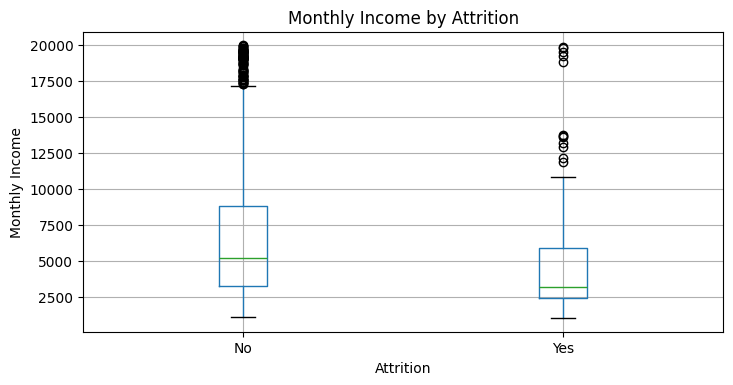

In [14]:
df.boxplot(column="MonthlyIncome", by="Attrition", figsize=(8, 4))

plt.title("Monthly Income by Attrition")
plt.suptitle("")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")
plt.show()



### 9.6 Age vs. Attrition

Compare employee ages between those who stayed and those who left.


In [15]:
df.groupby("Attrition")["Age"].agg(
    ["mean", "median"]
).round(2)


,mean,median
Attrition,,
No,37.56,36.0
Yes,33.61,32.0



### 9.7 Years at Company vs. Attrition

Compare company tenure between employees who stayed and those who left.


In [16]:

df.groupby("Attrition")["YearsAtCompany"].agg(
    ["mean", "median"]
).round(2)


,mean,median
Attrition,,
No,7.37,6.0
Yes,5.13,3.0



### 9.7 Years at Company vs. Attrition

Compare company tenure between employees who stayed and those who left.


In [17]:
df.groupby("Attrition")["YearsAtCompany"].agg(
    ["mean", "median"]
).round(2)


,mean,median
Attrition,,
No,7.37,6.0
Yes,5.13,3.0



### 9.8 Business Travel vs. Attrition

Compare attrition rates across different business travel frequencies.


In [18]:
travel_attrition = pd.crosstab(
    df["BusinessTravel"],
    df["Attrition"],
    normalize="index"
) * 100

travel_attrition.round(2)


Attrition,No,Yes
BusinessTravel,,
Non-Travel,92.00,8.00
Travel_Frequently,75.09,24.91
Travel_Rarely,85.04,14.96



### 9.9 Job Role vs. Attrition

Compare attrition rates across job roles and consider the size of each group.


In [19]:

job_role_attrition = pd.crosstab(
    df["JobRole"],
    df["Attrition"]
)

job_role_attrition["Attrition Rate (%)"] = (
    job_role_attrition["Yes"] / job_role_attrition.sum(axis=1) * 100
).round(2)

job_role_attrition.sort_values("Attrition Rate (%)", ascending=False)


Attrition,No,Yes,Attrition Rate (%)
JobRole,,,
Sales Representative,50,33,39.76
Laboratory Technician,197,62,23.94
Human Resources,40,12,23.08
Sales Executive,269,57,17.48
Research Scientist,245,47,16.10
Manufacturing Director,135,10,6.90
Healthcare Representative,122,9,6.87
Manager,97,5,4.90
Research Director,78,2,2.50



### 9.10 Work-Life Balance vs. Attrition

Compare employee attrition rates across work-life balance levels.


In [20]:

balance_attrition = pd.crosstab(
    df["WorkLifeBalance"],
    df["Attrition"],
    normalize="index"
) * 100

balance_attrition.round(2)


Attrition,No,Yes
WorkLifeBalance,,
1,68.75,31.25
2,83.14,16.86
3,85.78,14.22
4,82.35,17.65



### 9.11 Other Categorical Features

Explore attrition rates across additional employee characteristics.


In [21]:

categorical_features = [
    "EducationField",
    "Gender",
    "MaritalStatus",
    "EnvironmentSatisfaction",
    "JobInvolvement",
    "RelationshipSatisfaction",
    "StockOptionLevel",
    "JobLevel"
]

for col in categorical_features:
    table = pd.crosstab(df[col], df["Attrition"])

    table["Attrition Rate (%)"] = (
        table["Yes"] / table.sum(axis=1) * 100
    ).round(2)

    print(f"\n{col}")
    display(table.sort_values("Attrition Rate (%)", ascending=False))



EducationField


Attrition,No,Yes,Attrition Rate (%)
EducationField,,,
Human Resources,20,7,25.93
Technical Degree,100,32,24.24
Marketing,124,35,22.01
Life Sciences,517,89,14.69
Medical,401,63,13.58
Other,71,11,13.41



Gender


Attrition,No,Yes,Attrition Rate (%)
Gender,,,
Male,732,150,17.01
Female,501,87,14.80



MaritalStatus


Attrition,No,Yes,Attrition Rate (%)
MaritalStatus,,,
Single,350,120,25.53
Married,589,84,12.48
Divorced,294,33,10.09


... (6 outputs left out)


StockOptionLevel


Attrition,No,Yes,Attrition Rate (%)
StockOptionLevel,,,
0,477,154,24.41
3,70,15,17.65
1,540,56,9.40
2,146,12,7.59



JobLevel


Attrition,No,Yes,Attrition Rate (%)
JobLevel,,,
1,400,143,26.34
3,186,32,14.68
2,482,52,9.74
5,64,5,7.25
4,101,5,4.72



### 9.12 Other Numerical Features

Compare the median values of additional numerical features by attrition status.


In [22]:

numerical_features = [
    "DistanceFromHome",
    "TotalWorkingYears",
    "NumCompaniesWorked",
    "YearsInCurrentRole",
    "YearsSinceLastPromotion",
    "YearsWithCurrManager",
    "TrainingTimesLastYear"
]

df.groupby("Attrition")[numerical_features].median().T


Attrition,No,Yes
DistanceFromHome,7.0,9.0
TotalWorkingYears,10.0,7.0
NumCompaniesWorked,2.0,1.0
YearsInCurrentRole,3.0,2.0
YearsSinceLastPromotion,1.0,1.0
YearsWithCurrManager,3.0,2.0
TrainingTimesLastYear,3.0,2.0



### 9.13 Attrition Visualizations

Visualize attrition rates across key employee characteristics.


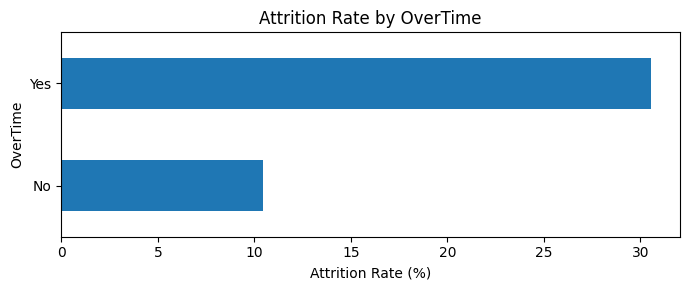

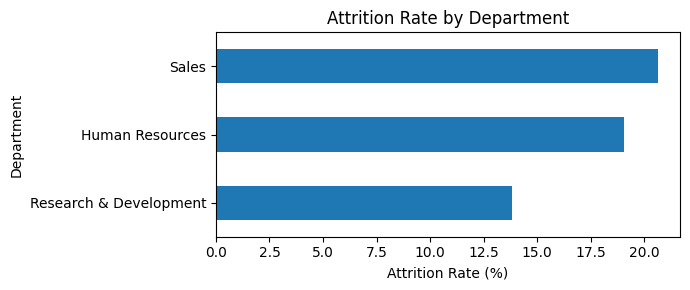

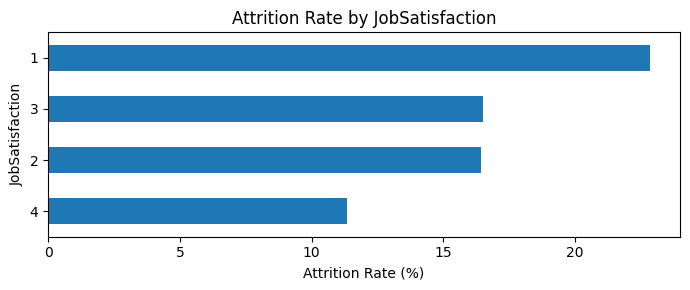

In [23]:

for col in ["OverTime", "Department", "JobSatisfaction"]:

    rates = pd.crosstab(
        df[col],
        df["Attrition"],
        normalize="index"
    )["Yes"] * 100

    rates.sort_values().plot(kind="barh", figsize=(7, 3))

    plt.title(f"Attrition Rate by {col}")
    plt.xlabel("Attrition Rate (%)")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()



## 10. Correlation with Attrition

Examine linear relationships between numerical features and employee attrition.


In [24]:

numeric_df = df.select_dtypes(include="number").drop(
    columns=["EmployeeCount", "EmployeeNumber", "StandardHours"]
)

numeric_df["AttritionFlag"] = (df["Attrition"] == "Yes").astype(int)

numeric_df.corr()["AttritionFlag"].drop(
    "AttritionFlag"
).sort_values().round(3)


TotalWorkingYears          -0.171
JobLevel                   -0.169
YearsInCurrentRole         -0.161
MonthlyIncome              -0.160
Age                        -0.159
YearsWithCurrManager       -0.156
StockOptionLevel           -0.137
YearsAtCompany             -0.134
JobInvolvement             -0.130
JobSatisfaction            -0.103
EnvironmentSatisfaction    -0.103
WorkLifeBalance            -0.064
TrainingTimesLastYear      -0.059
DailyRate                  -0.057
RelationshipSatisfaction   -0.046
YearsSinceLastPromotion    -0.033
Education                  -0.031
PercentSalaryHike          -0.013
HourlyRate                 -0.007
PerformanceRating           0.003
MonthlyRate                 0.015
NumCompaniesWorked          0.043
DistanceFromHome            0.078
Name: AttritionFlag, dtype: float64


## 11. Feature Correlations

Identify strong relationships between numerical features.


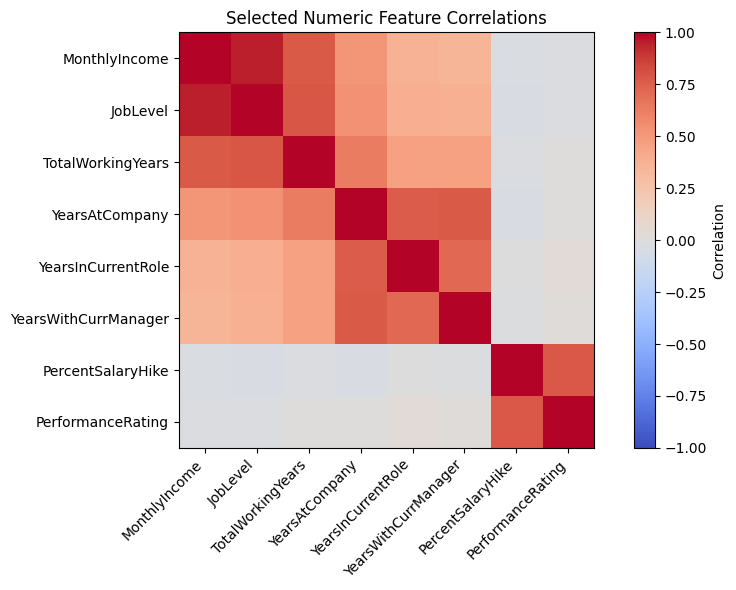

In [25]:

selected_features = [
    "MonthlyIncome",
    "JobLevel",
    "TotalWorkingYears",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsWithCurrManager",
    "PercentSalaryHike",
    "PerformanceRating"
]

corr = df[selected_features].corr()

plt.figure(figsize=(9, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.index)), corr.index)

plt.colorbar(label="Correlation")
plt.title("Selected Numeric Feature Correlations")
plt.tight_layout()
plt.show()



## 12. Outlier Detection

Identify potential numerical outliers using the IQR method.


In [26]:

outlier_counts = {}

for col in [
    "Age",
    "MonthlyIncome",
    "DistanceFromHome",
    "TotalWorkingYears",
    "YearsAtCompany"
]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    outlier_counts[col] = (
        (df[col] < q1 - 1.5 * iqr) |
        (df[col] > q3 + 1.5 * iqr)
    ).sum()

pd.Series(outlier_counts, name="Potential Outliers")



Age                    0
MonthlyIncome        114
DistanceFromHome       0
TotalWorkingYears     63
YearsAtCompany       104
Name: Potential Outliers, dtype: int64


## 13. Final Data Quality Checks




### 13.1 Placeholder Values

Check for text values that may represent missing information.

In [27]:

text_columns = df.select_dtypes(include="object").columns

placeholder_counts = df[text_columns].apply(
    lambda col: col.str.strip().str.lower().isin(
        ["", "unknown", "n/a", "na", "null", "none", "?"]
    ).sum()
)

placeholder_counts


Attrition         0
BusinessTravel    0
Department        0
EducationField    0
Gender            0
JobRole           0
MaritalStatus     0
Over18            0
OverTime          0
dtype: int64


### 13.2 Logical Consistency

Check employee IDs and basic numerical consistency rules.


In [28]:

checks = {
    "Duplicate EmployeeNumber": df["EmployeeNumber"].duplicated().sum(),
    "Age below 18": (df["Age"] < 18).sum(),
    "Invalid MonthlyIncome": (df["MonthlyIncome"] <= 0).sum(),
    "Negative YearsAtCompany": (df["YearsAtCompany"] < 0).sum(),

    "YearsAtCompany > TotalWorkingYears": (
        df["YearsAtCompany"] > df["TotalWorkingYears"]
    ).sum(),

    "YearsInCurrentRole > YearsAtCompany": (
        df["YearsInCurrentRole"] > df["YearsAtCompany"]
    ).sum(),

    "YearsSinceLastPromotion > YearsAtCompany": (
        df["YearsSinceLastPromotion"] > df["YearsAtCompany"]
    ).sum(),

    "YearsWithCurrManager > YearsAtCompany": (
        df["YearsWithCurrManager"] > df["YearsAtCompany"]
    ).sum()
}

pd.Series(checks, name="Invalid Records")


Duplicate EmployeeNumber                    0
Age below 18                                0
Invalid MonthlyIncome                       0
Negative YearsAtCompany                     0
YearsAtCompany > TotalWorkingYears          0
YearsInCurrentRole > YearsAtCompany         0
YearsSinceLastPromotion > YearsAtCompany    0
YearsWithCurrManager > YearsAtCompany       0
Name: Invalid Records, dtype: int64


## 14. Initial Feature Selection Plan

Identify candidate features for model development without modifying the original dataset.


In [29]:

excluded_columns = [
    "Attrition",
    "EmployeeNumber",
    "EmployeeCount",
    "Over18",
    "StandardHours"
]

candidate_features = df.drop(columns=excluded_columns).columns.tolist()

print("Candidate Features:", len(candidate_features))
print(candidate_features)


Candidate Features: 30
['Age', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
